# 02 — Taxa manual

**Pergunta de negócio.** Para um grupo sem histórico próprio (cotação nova), qual a mortalidade esperada
em relação à BR-EMSmt 2026, dada a atividade do estipulante e o capital das vidas?

**Modelo.** Modelo linear generalizado misto (GLMM) de Poisson, estimado no R com **glmmTMB** e conferido
com **lme4**. Em cada célula (estipulante × faixa etária × sexo × faixa de capital):

log μ = log E + β₀ + β_cap · log(capital / capital_ref) + β_seção + u_divisão + u_estipulante

- E: óbitos esperados pela tábua (offset). exp(β) e exp(u) são fatores A/E.
- **Seção CNAE como efeito fixo, divisão como efeito aleatório dentro da seção.** É a estrutura de Ohlsson
  (2008) para fatores com muitos níveis: cada divisão recebe credibilidade em torno da sua seção.
- **Estipulante como efeito aleatório:** separa o efeito da atividade do efeito do grupo e dá intervalos
  honestos (células do mesmo grupo não são independentes).

**Decisões tomadas antes de olhar os dados** (premissas de negócio, em `config/manual.yaml`):
1. Atividade e capital entram na tarifa: atividade é fator de subscrição padrão em vida e AP, e a
   mortalidade cai com o capital, num prêmio que é em R$. O capital entra como log contínuo (um parâmetro).
2. Faixa etária, sexo e porte são **candidatos**: entram só com evidência estatística (razão de
   verossimilhança, correção de Holm para testes múltiplos). Idade e sexo já estão na tábua; o teste mede o
   desvio adicional.
3. Estima-se em **contagem de óbitos**; o valor (R$) entra na renovação, com pooling.
4. Só entra experiência **maturada** (12 meses antes da data de referência), para o IBNR não viesar os fatores.

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import manual as M, glmm as G, verdade as V
from vgpricing.exposicao import exposicao_detalhada

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, cm, cs = carregar_config("base", RAIZ), carregar_config("manual", RAIZ), carregar_config("sintetico", RAIZ)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
assert not tabua.placeholder, "Tábua oficial não carregada"
assert G.r_disponivel(), "R com glmmTMB e lme4 não encontrado (veja o README)"

pasta = RAIZ / "data/synthetic"
if not (pasta / "limpo").exists():
    raise FileNotFoundError("Rode antes o notebook 01_dados (ele grava a base limpa em data/synthetic/limpo).")
dados = {t: pd.read_parquet(pasta / "limpo" / f"{t}.parquet") for t in ("estipulantes", "vidas", "sinistros")}
print(f"Tábua: {tabua.nome} | estipulantes: {len(dados['estipulantes'])} | segmentos de vida: {len(dados['vidas']):,}")

Tábua: BR-EMSmt-2026 | estipulantes: 250 | segmentos de vida: 863,864


## 1. Base de modelagem

In [2]:
cel, info = M.base_modelagem(dados["vidas"], dados["sinistros"], dados["estipulantes"], tabua,
                             cfg["data_referencia"], cm, cfg["exposicao"]["dias_por_ano"])
pd.Series({k: v for k, v in info.items() if k != "ids_sem_celula"}).to_frame("valor")

,valor
corte_experiencia,2024-12-31
sinistros_no_periodo,1725
sinistros_sem_celula,30
celulas_sexo_ND_removidas,1206
celulas,6463
estipulantes,250
obitos,1686
esperados,"1,627.3897"
secoes_agrupadas_em_OUTRAS,[]


Sinistros "sem célula" são de vidas sem exposição limpa na data do óbito (vida inexistente no cadastro,
ou segmento excluído na validação). Ficam fora do modelo e estão listados em `info["ids_sem_celula"]` para
investigação. Células com sexo ausente também ficam fora.

## 2. Primeira leitura: A/E por característica, sem ajuste

In [3]:
uni = pd.concat([cel.groupby(f, observed=True)[["E", "N"]].sum().assign(fator=f).rename_axis("nivel").reset_index()
                 for f in ["cnae_secao", "faixa_capital", "faixa_idade", "sexo", "faixa_tamanho"]])
uni["A/E"] = uni["N"] / uni["E"]
uni[["fator", "nivel", "E", "N", "A/E"]]

,fator,nivel,E,N,A/E
0,cnae_secao,C,200.3533,218,1.0881
1,cnae_secao,F,150.9667,186,1.2321
2,cnae_secao,G,68.1254,77,1.1303
3,cnae_secao,H,206.7769,300,1.4508
4,cnae_secao,K,133.3037,131,0.9827
5,cnae_secao,M,88.2555,68,0.7705
6,cnae_secao,N,277.0932,293,1.0574
7,cnae_secao,O,319.6548,254,0.7946
8,cnae_secao,P,116.8503,96,0.8216
9,cnae_secao,Q,66.0099,63,0.9544


O A/E univariado mistura efeitos: uma seção com grupos de capital alto parece melhor também por causa
do capital. O modelo separa isso.

## 3. Ajuste e escolha dos fatores candidatos

O modelo completo (obrigatórios + candidatos) é ajustado uma vez; cada candidato é testado retirando-o do
modelo (razão de verossimilhança), e os p-valores são corrigidos por Holm. Os efeitos aleatórios também
são testados (com o p-valor da mistura 50:50, porque a variância está na fronteira sob a hipótese nula),
mas ficam no modelo de qualquer forma: fazem parte da estrutura.

In [4]:
final, completo, testes = M.ajustar_taxa_manual(cel, cm, conferir_lme4=True)
print("Convergiu:", final.convergiu, "| fórmula final:", final.formula)
testes

Convergiu: True | fórmula final: N ~ log_capital_c + cnae_secao + (1 | cnae_secao:cnae_divisao) + (1 | id_estipulante) + offset(log(E))


,termo,tipo,lr,gl,p_valor,p_holm,decisao
0,faixa_idade,fixo,5.5732,4,0.2334,0.4667,não entra
1,sexo,fixo,0.0054,1,0.9412,0.9412,não entra
2,faixa_tamanho,fixo,7.8721,3,0.0487,0.1462,não entra
3,(1|cnae_secao:cnae_divisao),aleatorio,-0.0000,1,0.5000,NaN,estrutura (mantido)
4,(1|id_estipulante),aleatorio,10.1349,1,0.0007,NaN,estrutura (mantido)


Na carteira sintética, nenhum candidato entra: o gerador usa a própria tábua por idade e sexo e não tem
efeito de porte. Sem a correção de Holm, o porte teria entrado por acaso em algumas carteiras (p perto de
5%), o mesmo tipo de falso positivo que a seleção stepwise produzia antes.

## 4. Onde está a sobredispersão?

In [5]:
M.comparar_dispersao(cel, final)

,modelo,dispersão,loglik,parametros,AIC,dif_AIC_vs_melhor
0,GLM Poisson,nenhuma,"-2,615.4244",11,"5,252.8487",11.6349
1,Binomial Negativa (NB2),"por célula, independente","-2,615.0773",12,"5,254.1546",12.9408
2,GLMM (glmmTMB),por grupo e por atividade,"-2,607.6069",13,"5,241.2138",0.0000


A Binomial Negativa trata a sobredispersão como ruído independente por célula, e quase não melhora a
Poisson: a dispersão não está na célula. O GLMM a coloca onde ela está, no grupo e na atividade, e tem AIC
menor com log-verossimilhanças na mesma base.

## 5. Resultados

In [6]:
fx = final.fixos.copy()
fx["fator"] = np.exp(fx["estimativa"])
fx["ic95_inf"] = np.exp(fx["estimativa"] - 1.96 * fx["ep"])
fx["ic95_sup"] = np.exp(fx["estimativa"] + 1.96 * fx["ep"])
print("Nível base da seção (maior exposição):", final.especificacao["niveis_base"]["cnae_secao"])
fx

Nível base da seção (maior exposição): O


,nome,estimativa,ep,fator,ic95_inf,ic95_sup
0,(Intercept),-0.3063,0.0844,0.7362,0.6239,0.8687
1,log_capital_c,-0.0863,0.0326,0.9173,0.8605,0.9778
2,cnae_secaoC,0.3468,0.1202,1.4146,1.1178,1.7902
3,cnae_secaoF,0.5200,0.1295,1.6820,1.3048,2.1681
4,cnae_secaoG,0.4019,0.1555,1.4947,1.1021,2.0272
5,cnae_secaoH,0.6393,0.1192,1.8951,1.5002,2.3939
6,cnae_secaoK,0.2570,0.1416,1.2930,0.9797,1.7065
7,cnae_secaoM,0.0837,0.1755,1.0873,0.7709,1.5336
8,cnae_secaoN,0.3582,0.1131,1.4307,1.1463,1.7857
9,cnae_secaoP,0.0908,0.1549,1.0951,0.8083,1.4836


In [7]:
v = final.variancias
tv = pd.DataFrame({"variância (escala log)": v, "desvio-padrão": {k: np.sqrt(x) for k, x in v.items()},
                   "fator marginal exp(σ²/2)": {k: np.exp(x / 2) for k, x in v.items()}})
if final.ic_variancias is not None:
    tv = tv.join(final.ic_variancias.set_index("termo").rename(columns={"var_inf": "IC95 inf", "var_sup": "IC95 sup"}))
tv

,variância (escala log),desvio-padrão,fator marginal exp(σ²/2),IC95 inf,IC95 sup
cnae_secao:cnae_divisao,0.0000,0.0000,1.0000,0.0000,Inf
id_estipulante,0.0485,0.2202,1.0245,0.0232,0.1015


**Leitura:**
- **Capital:** a elasticidade é o efeito de dobrar o capital, exp(β_cap · ln 2). Negativa significa que vidas
  de capital maior morrem menos, na direção do gradiente de renda do gerador.
- **Estipulante:** a variância mede quanto os grupos diferem entre si além do que a atividade e o capital
  explicam. É o insumo da credibilidade da renovação (Etapa 3). **O intervalo é largo:** com mediana de
  cerca de 3 óbitos por grupo, a variância entre grupos é mal determinada. Na carteira deste notebook a
  estimativa fica abaixo da variância verdadeira do gerador (um estimador de momentos independente dá o
  mesmo resultado, então não é problema do software). Essa incerteza muda a credibilidade e é o principal
  motivo para a camada bayesiana (Etapa 5).
- **Divisão:** se a variância sair perto de zero, a leitura é que, com este volume, as divisões não se
  distinguem das suas seções; cada divisão fica com o fator da seção até haver dados. No gerador o desvio
  por divisão é de 10%, pequeno perto da heterogeneidade entre grupos.
- **Grupo novo:** como o efeito é Normal na escala log, o fator esperado de um grupo desconhecido é
  exp(σ²/2), não 1. A tabela de fatores já inclui essa correção; sem ela, a taxa manual sairia baixa.

### 5.1 Conferência com lme4 (mesma fórmula, outro software)

In [8]:
lme = pd.Series(dict(zip(final.lme4["fixos"]["nome"], final.lme4["fixos"]["estimativa"])))
conf = pd.DataFrame({"glmmTMB": final.fixos.set_index("nome")["estimativa"], "lme4": lme})
conf["diferença"] = conf["glmmTMB"] - conf["lme4"]
var_lme4 = {k: (x if not isinstance(x, list) else x[0]) for k, x in final.lme4["variancias"].items()}
print("Variâncias glmmTMB:", {k: round(x, 5) for k, x in final.variancias.items()})
print("Variâncias lme4:   ", {k: round(float(x), 5) for k, x in var_lme4.items()})
conf

Variâncias glmmTMB: {'cnae_secao:cnae_divisao': 0.0, 'id_estipulante': 0.0485}
Variâncias lme4:    {'id_estipulante': 0.04849, 'cnae_secao:cnae_divisao': 0.0}


,glmmTMB,lme4,diferença
(Intercept),-0.3063,-0.3062,-0.0001
log_capital_c,-0.0863,-0.0863,-0.0000
cnae_secaoC,0.3468,0.3468,0.0000
cnae_secaoF,0.5200,0.5200,0.0000
cnae_secaoG,0.4019,0.4019,-0.0000
cnae_secaoH,0.6393,0.6393,0.0000
cnae_secaoK,0.2570,0.2570,0.0000
cnae_secaoM,0.0837,0.0837,0.0000
cnae_secaoN,0.3582,0.3582,0.0000
cnae_secaoP,0.0908,0.0908,-0.0000


## 6. A complexidade muda o preço? Comparação em grupos que o modelo nunca viu

Validação cruzada deixando **grupos inteiros** de fora (5 partes): cada modelo é ajustado sem um quinto dos
grupos e prevê o total de óbitos de cada grupo deixado de fora. É o caso de uso da taxa manual: cotar um
grupo novo. Métrica: deviance de Poisson no total de cada grupo (menor é melhor) e a razão
previstos/observados (viés).

In [9]:
fixos_final = final.especificacao["fixos"]
previsores = {
    "BR-EMS pura (A/E = 1)": lambda tr, te: te["E"].to_numpy(),
    "BR-EMS × A/E da carteira": lambda tr, te: te["E"].to_numpy() * tr["N"].sum() / tr["E"].sum(),
    "GLM Poisson (seção + capital)": lambda tr, te: M.glm_poisson(tr).predict(te, offset=np.log(te["E"])).to_numpy(),
    "Binomial Negativa (seção + capital)": lambda tr, te: np.asarray(M.glm_nb2(tr).predict(te, offset=np.log(te["E"]))),
    "GLMM (modelo final)": lambda tr, te: G.prever(M._ajustar(tr, cm, fixos_final), te),
}
cv = M.validacao_cruzada_grupos(cel, previsores, **{"k": cm["validacao_cruzada"]["folds"],
                                                     "semente": cm["validacao_cruzada"]["semente"]})
cv.sort_values("deviance_grupos_novos")

,modelo,deviance_grupos_novos,previstos/observados,dif_vs_melhor
2,GLM Poisson (seção + capital),386.1920,1.0199,0.0000
3,Binomial Negativa (seção + capital),386.7944,1.0220,0.6024
4,GLMM (modelo final),387.2328,1.0246,1.0408
0,BR-EMS pura (A/E = 1),431.0929,0.9652,44.9010
1,BR-EMS × A/E da carteira,432.4932,1.0008,46.3012


Os pontos estimados do GLM e do GLMM tendem a ser parecidos; a diferença maior está na **incerteza**
(o GLM trata as células de um grupo como independentes) e no **encolhimento** das divisões. A validação
definitiva, com o preço que de fato seria cobrado, é o backtest fora do tempo da Etapa 6, que roda igual
na base real.

## 7. Teste de software: o estimador recupera o que foi plantado?

Só existe na carteira sintética. **Não é evidência sobre o mercado**: mostra que o código estima
corretamente quando as hipóteses valem.

In [10]:
verd = pd.read_parquet(pasta / "verdade_estipulantes.parquet")
base = final.especificacao["niveis_base"]["cnae_secao"]
coef = final.fixos.set_index("nome")
linhas = []
for s in sorted(cel["cnae_secao"].unique()):
    b = coef.loc[f"cnae_secao{s}", "estimativa"] if s != base else 0.0
    ep = coef.loc[f"cnae_secao{s}", "ep"] if s != base else 0.0
    linhas.append({"seção": s, "estimado": np.exp(b), "ic95_inf": np.exp(b - 1.96 * ep), "ic95_sup": np.exp(b + 1.96 * ep)})
t = pd.DataFrame(linhas).set_index("seção")
t["verdade"] = V.relatividades_secao(verd, base).reindex(t.index)
t["IC cobre a verdade"] = (t["ic95_inf"] <= t["verdade"]) & (t["verdade"] <= t["ic95_sup"])
t

,estimado,ic95_inf,ic95_sup,verdade,IC cobre a verdade
seção,,,,,
C,1.4146,1.1178,1.7902,1.2105,True
F,1.6820,1.3048,2.1681,1.4211,True
G,1.4947,1.1021,2.0272,1.1053,True
H,1.8951,1.5002,2.3939,1.3684,False
K,1.2930,0.9797,1.7065,0.8947,False
M,1.0873,0.7709,1.5336,0.9474,True
N,1.4307,1.1463,1.7857,1.0526,False
O,1.0000,1.0000,1.0000,1.0000,True
P,1.0951,0.8083,1.4836,0.9474,True


Comparar com um nível base faz o erro da própria seção base contaminar todas as relatividades; além
disso, a variância entre grupos subestimada nesta carteira (seção 5) estreita os intervalos. Por isso a
cobertura numa única carteira não é conclusiva. A calibração dos intervalos é medida de forma
sistemática na Etapa 6.

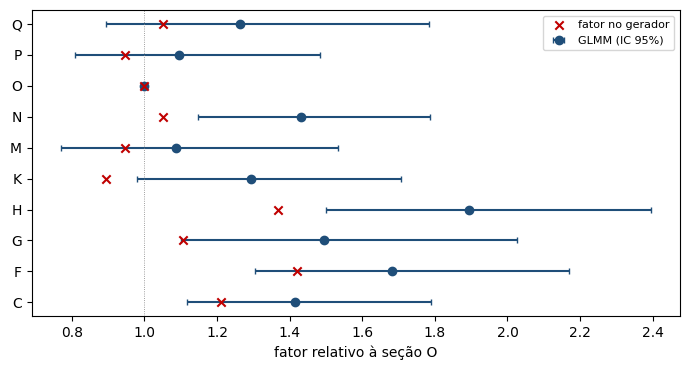

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.8)); y = np.arange(len(t))
ax.errorbar(t["estimado"], y, xerr=[t["estimado"] - t["ic95_inf"], t["ic95_sup"] - t["estimado"]], fmt="o",
            color="#1f4e79", capsize=2, label="GLMM (IC 95%)")
ax.scatter(t["verdade"], y, marker="x", color="#c00000", zorder=5, label="fator no gerador")
ax.set_yticks(y, t.index); ax.axvline(1, color="grey", lw=0.6, ls=":")
ax.set_xlabel(f"fator relativo à seção {base}"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 8. Tabela de fatores para o cotador

In [12]:
meta = {"gerado_em": pd.Timestamp.today().date().isoformat(), "fonte_dados": "carteira sintética",
        "tabua": tabua.nome, "tabua_sha256": tabua.sha256, "corte_experiencia": info["corte_experiencia"],
        "obitos": info["obitos"], "esperados_tabua": round(info["esperados"], 2),
        "software": "R glmmTMB (conferido com lme4)",
        "candidatos_testados": cm["modelo"]["fixos_candidatos"],
        "candidatos_que_entraram": [f for f in final.especificacao["fixos"] if f in cm["modelo"]["fixos_candidatos"]],
        "secoes_agrupadas_em_OUTRAS": info["secoes_agrupadas_em_OUTRAS"],
        "esperados_por_secao": cel.groupby("cnae_secao")["E"].sum().round(3).to_dict()}
tabela = M.tabela_fatores(final, cm, meta)
M.salvar_tabela(tabela, RAIZ / "artefatos/fatores_manual.yaml")
pd.Series({"A/E base (grupo novo, seção base, capital de referência)": tabela["ae_base"],
           "elasticidade ao capital": tabela["capital"]["elasticidade"],
           "fator ao dobrar o capital": 2 ** tabela["capital"]["elasticidade"],
           "fator para seção sem experiência": tabela["secao_nao_vista"],
           "fator para divisão sem experiência": tabela["divisao_nao_vista"]}).to_frame("valor")

,valor
"A/E base (grupo novo, seção base, capital de referência)",0.7543
elasticidade ao capital,-0.0863
fator ao dobrar o capital,0.9419
fator para seção sem experiência,1.3683
fator para divisão sem experiência,1.0000


## 9. Exemplo: taxa pura manual de um grupo

In [13]:
ref = pd.Timestamp(cfg["data_referencia"])
ativos = dados["vidas"][dados["vidas"]["data_fim"].isna()]
porte = ativos["id_estipulante"].value_counts()
grupo = porte.index[len(porte) // 2]                                    # um grupo de porte mediano
censo = ativos[ativos["id_estipulante"] == grupo]
e = dados["estipulantes"].set_index("id_estipulante").loc[grupo]
cot = M.taxa_pura_manual(censo, e["cnae_secao"], e["cnae_divisao"], tabela, tabua, ref + pd.Timedelta(days=1))
pd.Series({"estipulante": grupo, "atividade (seção:divisão)": f"{e['cnae_secao']}:{e['cnae_divisao']}",
           "vidas": cot["vidas"], "capital total (R$)": cot["capital_total"], "fator de atividade": cot["fator_atividade"],
           "óbitos esperados/ano": cot["obitos_esperados"], "prêmio puro anual (R$)": cot["premio_puro_anual"],
           "taxa pura anual (‰)": cot["taxa_pura_anual_mil"], "taxa pura mensal (‰)": cot["taxa_pura_mensal_mil"],
           "avisos": "; ".join(cot["avisos"]) or "nenhum"}).to_frame("cotação")

,cotação
estipulante,EST0247
atividade (seção:divisão),P:85
vidas,451
capital total (R$),"56,886,300.0000"
fator de atividade,1.0951
óbitos esperados/ano,0.7579
prêmio puro anual (R$),"89,542.3977"
taxa pura anual (‰),1.5741
taxa pura mensal (‰),0.1312
avisos,nenhum


A taxa comercial (carregamentos, impostos, corretagem) e o reajuste de renovação entram no cotador e na
Etapa 3.

## Limitações
- **Dados sintéticos:** os fatores refletem as hipóteses do gerador. Com a base real, o mesmo procedimento
  roda de novo; o código não muda.
- **Poder estatístico:** com cerca de 1.700 óbitos, efeitos pequenos (divisão, capital) ficam perto do ruído.
  O encolhimento cuida disso: com mais volume, os fatores se afastam de 1 sem decisão nova.
- **Efeito Normal na escala log:** é o padrão do software. Implica a correção exp(σ²/2) para grupos novos,
  já aplicada.
- **Incerteza dos parâmetros:** o GLMM estima as variâncias e as trata como conhecidas na previsão. Propagar
  essa incerteza para o preço é o papel da camada bayesiana (Etapa 5).
- **Seções raras:** com pouca exposição, são agrupadas em "OUTRAS"; o limite está no config.